# 04 — SHAP explanations on held-out test examples
Explanations refer to the **uncalibrated** classifier output; isotonic calibration changes probabilities and is not included in SHAP attribution.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from lead_scoring_utils import *

import joblib, shap, matplotlib.pyplot as plt

bundle = joblib.load(BASE / 'models' / 'lead_scoring_pipeline_v2.joblib')

pipeline=bundle['pipeline']
_,_,test=load_split()
X=prepare(test)
Z=pipeline.named_steps['preprocess'].transform(X)
names=pipeline.named_steps['preprocess'].get_feature_names_out()
est=pipeline.named_steps['model']
sample=Z[:min(100,len(Z))]
if bundle['pipeline'].named_steps['model'].__class__.__name__ in ('XGBClassifier','RandomForestClassifier'):
    explainer=shap.TreeExplainer(est)
else:
    explainer=shap.LinearExplainer(est,Z[:min(200,len(Z))])
values=explainer(sample)
print('Explained',len(sample),'held-out leads using',type(est).__name__)

Explained 100 held-out leads using XGBClassifier


In [6]:
# Attach actual transformed feature names to SHAP explanations
values.feature_names = list(feature_names)

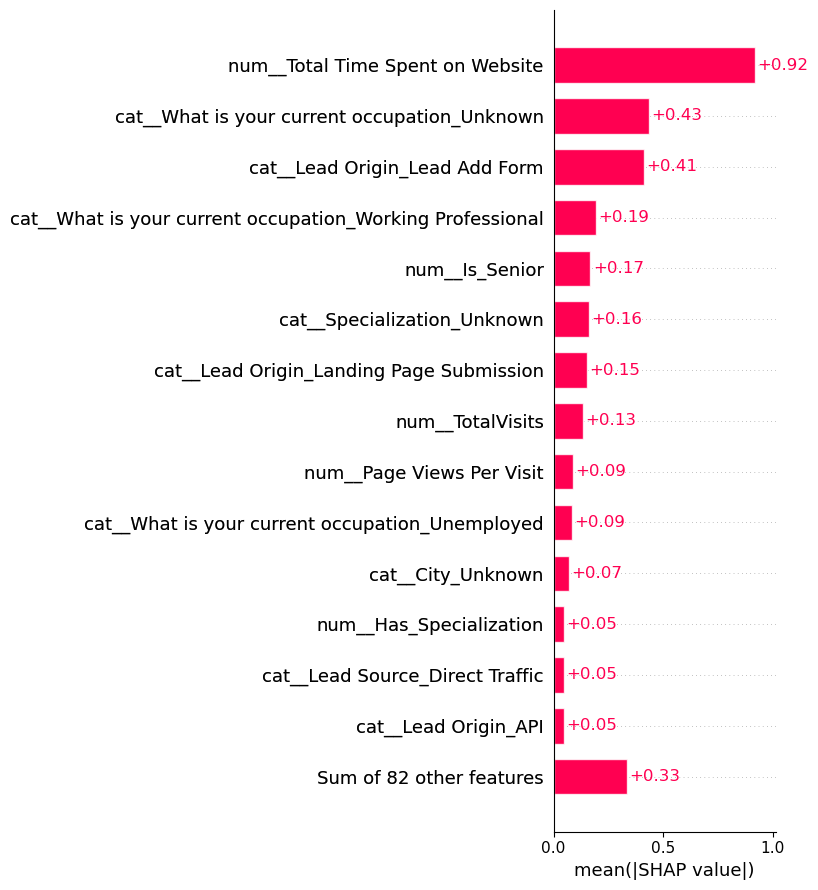

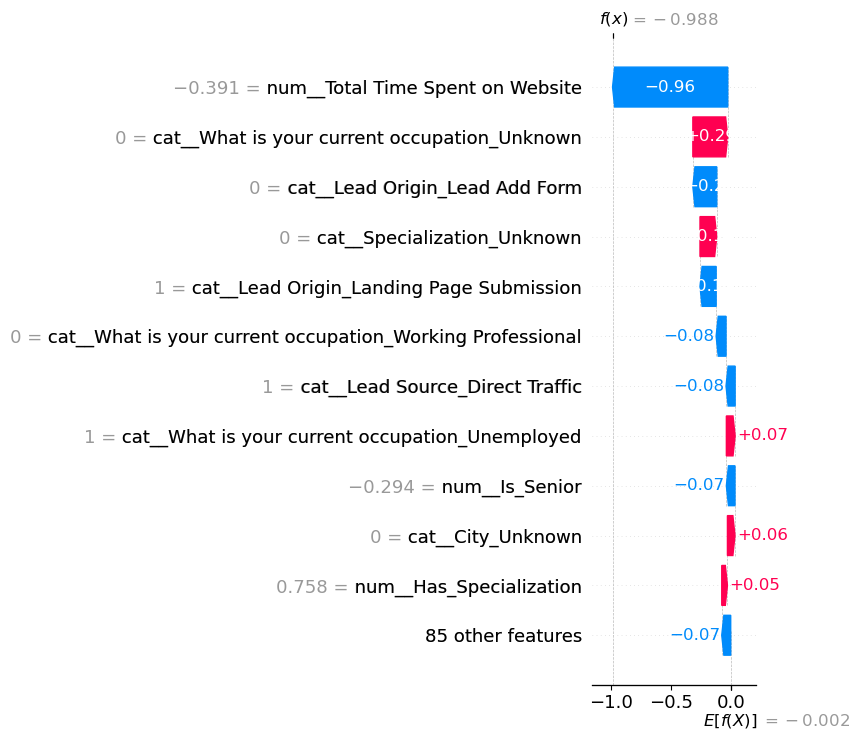

In [7]:
# Global SHAP explanation
shap.plots.bar(values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(
    BASE / 'images' / 'shap_global.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

# Local SHAP explanation
shap.plots.waterfall(values[0], max_display=12, show=False)
plt.tight_layout()
plt.savefig(
    BASE / 'images' / 'shap_local.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

In [3]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 2.0.3


In [5]:
feature_names = pipeline.named_steps['preprocess'].get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFirst 15 feature names:")
print(feature_names[:15])

print("\nSHAP input columns:", Z.shape[1])

Total transformed features: 96

First 15 feature names:
['cat__Lead Origin_API' 'cat__Lead Origin_Landing Page Submission'
 'cat__Lead Origin_Lead Add Form' 'cat__Lead Origin_Lead Import'
 'cat__Lead Origin_Quick Add Form' 'cat__Lead Source_Click2call'
 'cat__Lead Source_Direct Traffic' 'cat__Lead Source_Facebook'
 'cat__Lead Source_Google' 'cat__Lead Source_Live Chat'
 'cat__Lead Source_Olark Chat' 'cat__Lead Source_Organic Search'
 'cat__Lead Source_Press_Release' 'cat__Lead Source_Reference'
 'cat__Lead Source_Referral Sites']

SHAP input columns: 96
